**Nawaf Khalid Alsabr**  
**ID: 2230004159**

# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

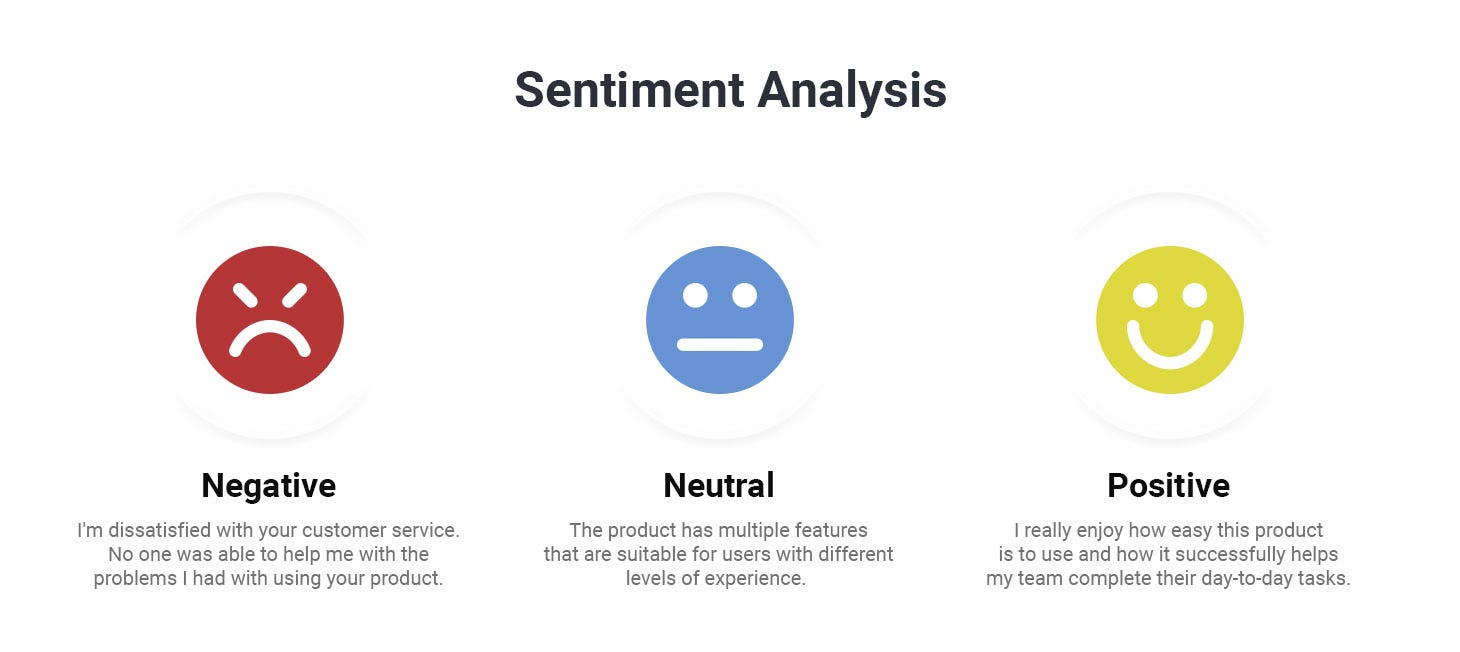

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
import pandas as pd

data = pd.read_csv('DisneylandReviews.csv', encoding='latin-1')
data


,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:
              precision    recall  f1-score   support

    negative       0.64      0.54      0.59       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.97      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluation the model on the Test Set

Task6: Print the Confusion Matrix

## Solving the Tasks: Amazon Unlocked Mobile Phones Sentiment Analysis

We follow the same overall approach used for the Disneyland reviews, applied here to the Amazon Unlocked Mobile Phones reviews dataset.

### Task 1: Load the data and do 5 different preprocessing steps

The 5 preprocessing steps applied below are:
1. Drop rows with missing/empty review text
2. Map star ratings (1-5) to sentiment labels (positive / negative / neutral)
3. Lowercase all text
4. Remove punctuation, digits and special characters
5. Remove extra whitespace

In [9]:
import pandas as pd

amazon_data = pd.read_csv('Amazon_Unlocked_Mobile.csv', encoding='latin-1')
print(amazon_data.shape)
amazon_data.head()


(413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [10]:
import re

# Step 1: Drop rows with missing review text or rating
amazon_data = amazon_data.dropna(subset=['Reviews', 'Rating'])

# Step 2: Map star ratings to sentiment
amazon_data['Sentiment'] = amazon_data['Rating'].apply(
    lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral')
)

def preprocess_text(text):
    # Step 3: Lowercase
    text = text.lower()
    # Step 4: Remove punctuation, digits and special characters
    text = re.sub(r'[^a-z\s]', '', text)
    # Step 5: Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    return text

amazon_data['Reviews'] = amazon_data['Reviews'].apply(preprocess_text)

# Drop any reviews that became empty after cleaning
amazon_data = amazon_data[amazon_data['Reviews'].str.len() > 0]

print(f"Rows after preprocessing: {len(amazon_data)}")
print(amazon_data['Sentiment'].value_counts())
amazon_data[['Reviews', 'Sentiment']].head()


Rows after preprocessing: 413248
Sentiment
positive    284457
negative     97038
neutral      31753
Name: count, dtype: int64


,Reviews,Sentiment
0,i feel so lucky to have found this used phone ...,positive
1,nice phone nice up grade from my pantach revue...,positive
2,very pleased,positive
3,it works good but it goes slow sometimes but i...,positive
4,great phone to replace my lost phone the only ...,positive


The full dataset has 400k+ reviews. For reasonable training time, we take a stratified random sample of 50,000 reviews (keeping the same class proportions) before moving on.

In [11]:
sample_frac = 50000 / len(amazon_data)
sampled_parts = [g.sample(frac=sample_frac, random_state=42) for _, g in amazon_data.groupby('Sentiment')]
amazon_sample = pd.concat(sampled_parts)

print(f"Sample size: {len(amazon_sample)}")
print(amazon_sample['Sentiment'].value_counts())


Sample size: 50000
Sentiment
positive    34417
negative    11741
neutral      3842
Name: count, dtype: int64


### Task 2: Use a proper train and test split

In [12]:
from sklearn.model_selection import train_test_split

amazon_train_data, amazon_test_data, amazon_train_labels, amazon_test_labels = train_test_split(
    amazon_sample['Reviews'],
    amazon_sample['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=amazon_sample['Sentiment']
)

print(f"train_data size: {amazon_train_data.shape}")
print(f"test_data size: {amazon_test_data.shape}")


train_data size: (40000,)
test_data size: (10000,)


### Task 3: Feature Extraction Using TF-IDF

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

amazon_tfidf_vectorizer = TfidfVectorizer(max_features=1000)
amazon_train_vectors = amazon_tfidf_vectorizer.fit_transform(amazon_train_data)
amazon_test_vectors = amazon_tfidf_vectorizer.transform(amazon_test_data)

print(f"Train vectors shape: {amazon_train_vectors.shape}")
print(f"Test vectors shape: {amazon_test_vectors.shape}")


Train vectors shape: (40000, 1000)
Test vectors shape: (10000, 1000)


### Task 4: Train a Naive Bayes Classifier

In [14]:
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(amazon_train_vectors, amazon_train_labels)


,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


### Task 5: Evaluate the model on the Test Set

In [15]:
from sklearn.metrics import accuracy_score, classification_report

amazon_predictions = nb_classifier.predict(amazon_test_vectors)

amazon_accuracy = accuracy_score(amazon_test_labels, amazon_predictions)
print(f"Accuracy: {amazon_accuracy:.2f}")

print("Classification Report:")
print(classification_report(amazon_test_labels, amazon_predictions))


Accuracy: 0.83
Classification Report:
              precision    recall  f1-score   support

    negative       0.78      0.68      0.73      2348
     neutral       0.37      0.01      0.02       768
    positive       0.84      0.97      0.90      6884

    accuracy                           0.83     10000
   macro avg       0.66      0.55      0.55     10000
weighted avg       0.79      0.83      0.79     10000



### Task 6: Print the Confusion Matrix

Confusion Matrix:
[[1602    2  744]
 [ 225    7  536]
 [ 218   10 6656]]


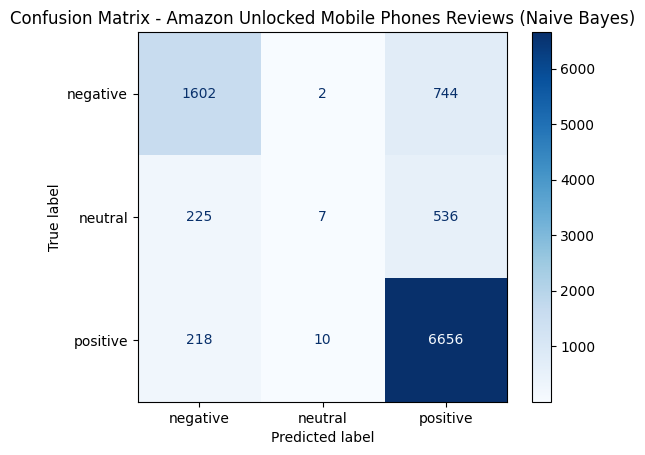

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels_order = ['negative', 'neutral', 'positive']
cm = confusion_matrix(amazon_test_labels, amazon_predictions, labels=labels_order)
print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Amazon Unlocked Mobile Phones Reviews (Naive Bayes)')
plt.show()


**Summary:** After cleaning ~400k Amazon phone reviews (dropping missing values, mapping ratings to sentiment, lowercasing, stripping punctuation/digits, and collapsing whitespace) and taking a stratified 50,000-review sample, we trained a Multinomial Naive Bayes classifier on TF-IDF features. The class distribution is imbalanced (most reviews are 5-star/positive), which is reflected in the per-class precision/recall in the classification report and in the confusion matrix, where the model performs best on the majority "positive" class and struggles more to distinguish "neutral" reviews from the other two classes.